# Rejon SRLM na wycinku z OSM

Ustaw `REJON` w pierwszej komórce kodu (numer `NR_REJ` z `data/SRLM/`) i uruchom całość. Notatnik rysuje rejon na tle obrysów budynków z OpenStreetMap, kwadratów spisu NSP 2021 (125 m) i funkcji budynków z BDOT10k. Dane z `data/`: `SRLM/`, `osm_budynki_*.geojson`, `populacja/`. Dla rejonu, którego obszaru jeszcze nie ma w `data/`, obrysy OSM pobierają się raz przez Overpass (potrzebna sieć); modelem nic się nie liczy.


In [5]:
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 88}}

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from agenci.srlm import obszar_pracy, udzialy_w_rejonach, wczytaj_srlm
from agenci.statystyka import wczytaj_nsp
from ortofoto.budynki import wczytaj_budynki, wczytaj_osm

REJON = 367  # numer rejonu SRLM (NR_REJ); zmień i uruchom całość od nowa

rejon = wczytaj_srlm([REJON])
granica = rejon.geometry.iloc[0]
obszar = obszar_pracy(granica)  # kwadraty NSP przecinające rejon
nazwa = f"{REJON} ({rejon.nazwa.iloc[0]})"
osm = wczytaj_osm(obszar)  # przy nowym obszarze pobiera obrysy z Overpass i zapisuje w data/
nsp = wczytaj_nsp(granica)
nsp = nsp[nsp.intersection(granica).area > 1]
bud = wczytaj_budynki(obszar)  # BDOT10k z dołączonym OSM; funkcja budynku pochodzi z BDOT10k
u = udzialy_w_rejonach(bud, rejon)
w_rejonie = bud.loc[u[u > 0.5].index.get_level_values("id")]  # budynek należy do rejonu, jeśli ma w nim większość obrysu (jak w ewaluacji)
display(Markdown(f"**{rejon.nazwa.iloc[0]}**: SRLM {rejon.ludnosc.iloc[0]:.0f} os., powierzchnia {granica.area / 1e4:.1f} ha. "
                 f"Kwadratów NSP z częścią w rejonie: {len(nsp)} (łącznie {nsp.ludnosc.sum():.0f} os., kwadraty wystają poza rejon). "
                 f"Budynków BDOT10k w rejonie: {len(w_rejonie)} (w całym obszarze pracy: {len(bud)}, w OSM: {len(osm)}).")) 

**Piastowska**: SRLM 5737 os., powierzchnia 16.4 ha. Kwadratów NSP z częścią w rejonie: 23 (łącznie 7207 os., kwadraty wystają poza rejon). Budynków BDOT10k w rejonie: 198 (w całym obszarze pracy: 338, w OSM: 524).

## Granica rejonu i kwadraty spisu

Czerwony kontur to rejon SRLM, niebieskie kwadraty to siatka NSP z liczbą osób wg spisu. Kwadraty przy brzegu wystają poza rejon, więc spis nie da się porównać z SRLM wprost.

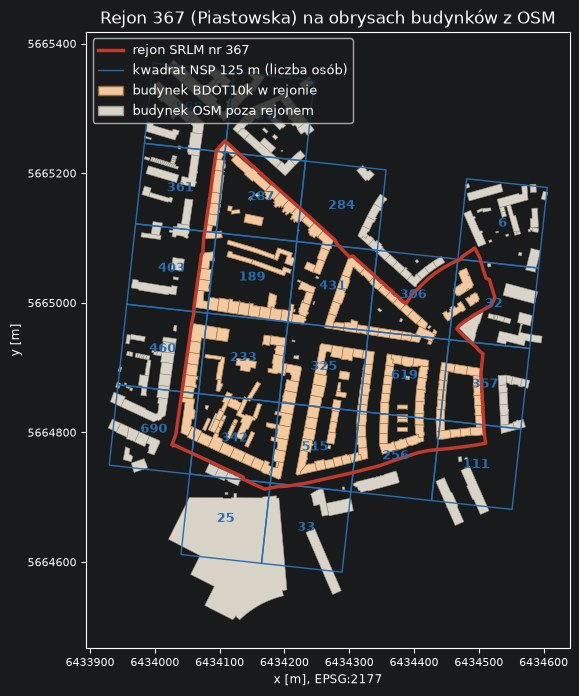

In [6]:
fig, ax = plt.subplots(figsize=(11, 8))
osm.plot(ax=ax, color="#d9d4c7", edgecolor="#9c968a", linewidth=0.4)
w_rejonie.plot(ax=ax, color="#f2c9a0", edgecolor="#9c6a3a", linewidth=0.4)  # obrysy z BDOT10k
nsp.boundary.plot(ax=ax, color="#2a6db0", linewidth=1)
for _, k in nsp.iterrows():
    c = k.geometry.centroid
    ax.annotate(f"{k.ludnosc:.0f}", (c.x, c.y), ha="center", va="center", fontsize=9, color="#2a6db0", fontweight="bold")
rejon.boundary.plot(ax=ax, color="#c0392b", linewidth=2.5)
ax.set_aspect("equal"); ax.set_xlabel("x [m], EPSG:2177"); ax.set_ylabel("y [m]")
ax.ticklabel_format(style="plain", useOffset=False); ax.tick_params(labelsize=8)
ax.legend(handles=[Line2D([], [], color="#c0392b", lw=2.5, label=f"rejon SRLM nr {REJON}"), Line2D([], [], color="#2a6db0", lw=1, label="kwadrat NSP 125 m (liczba osób)"),
                   Patch(facecolor="#f2c9a0", edgecolor="#9c6a3a", label="budynek BDOT10k w rejonie"), Patch(facecolor="#d9d4c7", edgecolor="#9c968a", label="budynek OSM poza rejonem")], loc="upper left", fontsize=9)
ax.set_title(f"Rejon {nazwa} na obrysach budynków z OSM"); plt.show()

## Funkcja budynków rejonu (BDOT10k)

Funkcję bierzemy z BDOT10k (`przewazajacaFunkcjaBudynku`), a OSM służy za adres i uzupełnienie kondygnacji. Liczone są budynki, których większość obrysu leży w rejonie.

In [3]:
funkcje = w_rejonie.funkcja.value_counts()
tab = w_rejonie.assign(pow_m2=w_rejonie.area.round(0)).groupby("funkcja").agg(budynki=("pow_m2", "size"), pow_m2=("pow_m2", "sum"), kondygnacje=("kondygnacje", "median")).sort_values("pow_m2", ascending=False)
display(tab)
mieszk = w_rejonie.mieszkalny_bdot & (w_rejonie.kategoria == "eksploatowany")
display(Markdown(f"Mieszkalne i eksploatowane wg BDOT10k: **{int(mieszk.sum())}** z {len(w_rejonie)} budynków. Z adresem z OSM: {int(w_rejonie['addr:street'].notna().sum())}.")) 
display(w_rejonie.assign(pow_m2=w_rejonie.area.round(0))[["funkcja", "kategoria", "kondygnacje", "h", "pow_m2", "addr:street", "addr:housenumber"]].sort_values("pow_m2", ascending=False).head(15).round(1))

,budynki,pow_m2,kondygnacje
funkcja,,,
centrum handlowe,1,24038.0,6.0
szkoła wyższa,8,10078.0,4.0
siedziba firmy lub firm,6,4137.0,6.0
budynek wielorodzinny,7,1707.0,5.0
dom studencki,1,1467.0,8.0
inny urząd administracji publicznej,1,793.0,4.0
warsztat remontowo-naprawczy,1,762.0,1.0
obiekt handlowo-usługowy,1,555.0,1.0
garaż,1,233.0,1.0


Mieszkalne i eksploatowane wg BDOT10k: **8** z 30 budynków. Z adresem z OSM: 8.

,funkcja,kategoria,kondygnacje,h,pow_m2,addr:street,addr:housenumber
id,,,,,,,
2881C5D6-8063-CEB0-E053-CC2BA8C034D4,centrum handlowe,eksploatowany,6.0,18.2,24038.0,plac Grunwaldzki,22
2881C5D6-81FD-CEB0-E053-CC2BA8C034D4,szkoła wyższa,eksploatowany,4.0,16.1,3329.0,NaN,NaN
2881C5D6-8659-CEB0-E053-CC2BA8C034D4,szkoła wyższa,eksploatowany,5.0,23.0,2240.0,NaN,NaN
2881C5D7-3392-CEB0-E053-CC2BA8C034D4,szkoła wyższa,eksploatowany,5.0,19.2,2146.0,NaN,NaN
A8E4A427-9639-412F-A8DD-AB995FFCB4C6,siedziba firmy lub firm,eksploatowany,6.0,25.4,2043.0,NaN,NaN
2881C5D6-7C48-CEB0-E053-CC2BA8C034D4,szkoła wyższa,eksploatowany,4.0,18.9,1762.0,NaN,NaN
2881C5D6-690B-CEB0-E053-CC2BA8C034D4,dom studencki,eksploatowany,8.0,25.9,1467.0,NaN,NaN
9E389E63-594D-46FE-A67E-631DF6873FF3,siedziba firmy lub firm,eksploatowany,6.0,23.6,1245.0,NaN,NaN
2881C5D6-4F02-CEB0-E053-CC2BA8C034D4,inny urząd administracji publicznej,eksploatowany,4.0,18.1,793.0,NaN,NaN


## Mapa: funkcja budynku z BDOT10k

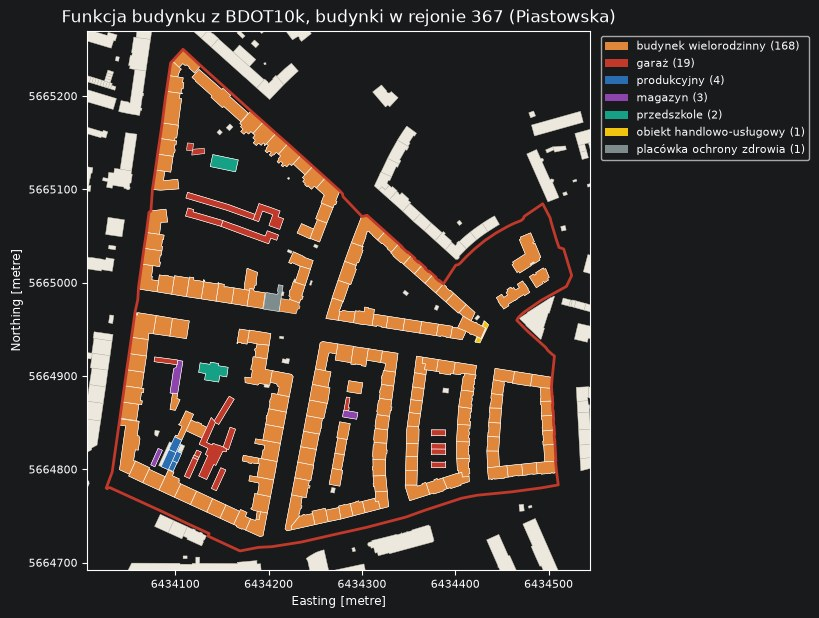

In [9]:
paleta = ["#e0873c", "#c0392b", "#2a6db0", "#8e44ad", "#16a085", "#f1c40f", "#7f8c8d", "#d35400", "#27ae60", "#34495e", "#e84393", "#95a5a6"]
funkcje = w_rejonie.funkcja.value_counts()  # liczone tu od nowa, żeby mapa nie zależała od stanu z innych komórek
kolory = {f: paleta[i % len(paleta)] for i, f in enumerate(funkcje.index)}
fig, ax = plt.subplots(figsize=(10, 7))
x0, y0, x1, y1 = granica.bounds
osm.plot(ax=ax, color="#ece8de", edgecolor="#cfc9ba", linewidth=0.3)
for f, g in w_rejonie.groupby("funkcja"):
    g.plot(ax=ax, color=kolory[f], edgecolor="white", linewidth=0.4)
rejon.boundary.plot(ax=ax, color="#c0392b", linewidth=2)
ax.set_xlim(x0 - 20, x1 + 20); ax.set_ylim(y0 - 20, y1 + 20); ax.set_aspect("equal"); ax.ticklabel_format(style="plain", useOffset=False); ax.tick_params(labelsize=8)
ax.legend(handles=[Patch(facecolor=kolory[f], label=f"{f} ({n})") for f, n in funkcje.items()], fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title(f"Funkcja budynku z BDOT10k, budynki w rejonie {nazwa}"); plt.show()